In [287]:
import glob as gl
import json
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
import pandas as pd
import scikit_posthocs as sp
from scipy.stats import ks_2samp, kruskal,ttest_ind,spearmanr,pearsonr
from scipy import stats
import seaborn as sns
import shutil


In [288]:
op_folder = "../Figures/CNIH2_local_synthesis"
def CreateFolderRecursive(folder):
    """
        function creates folders upto  a path recursively
        arguments : folderpath
    """
    Path(folder).mkdir(parents=True, exist_ok=True)
CreateFolderRecursive(op_folder)

In [294]:
# All metadata
in_folder = "../Protein/cLTP_CNIH-2"

treatments = ["cntl","cntl_cnih2","cltp_cnih2"]
x_labels = ["Control","CNIH-2","cLTP CNIH-2"]
compartments = ["soma","dendrite"]
CreateFolderRecursive("./Protein_data/cltp_CNIH2_GluA2")
cltp_cnih2_glua2_file = "./Protein_data/cltp_CNIH2_GluA2/cLTP_CNIH2_GluA2.pkl"
cltp_cnih2_glua2_meta_file = "./Protein_data/cltp_CNIH2_GluA2/cLTP_CNIH2_GluA2_meta_old.pkl"

In [295]:
CNIH_glua2_cltp_data = pd.read_pickle(cltp_cnih2_glua2_file)
CNIH_glua2_cltp_meta_data = pd.read_pickle(cltp_cnih2_glua2_meta_file)
cell_data = CNIH_glua2_cltp_data.groupby(["cell_id","treatment","compartment"])
cell_meta_data = CNIH_glua2_cltp_meta_data.groupby(["cell_id","treatment","compartment"])

In [296]:
x = np.vstack([CNIH_glua2_cltp_data.cell_id.tolist(),CNIH_glua2_cltp_data.treatment.tolist()])
print(x)

[['1' '1' '1' ... '31' '31' '31']
 ['cntl' 'cntl' 'cntl' ... 'cltp_cnih2' 'cltp_cnih2' 'cltp_cnih2']]


In [297]:
newprot_counts = CNIH_glua2_cltp_data.groupby(["cell_id","treatment","compartment"]).count().PID
# newprot_counts.PID

In [298]:
ROI_areas = cell_meta_data.sum().ROI_AOL
ROI_areas

cell_id  treatment   compartment
1        cltp_cnih2  dendrite        56.132455
                     soma           358.273300
         cntl        dendrite       408.036809
                     soma           348.938600
         cntl_cnih2  dendrite       200.586909
                                       ...    
45       cntl        soma           988.062100
46       cntl        dendrite       141.630729
                     soma           318.940400
47       cntl        dendrite       221.245273
                     soma           558.926000
Name: ROI_AOL, Length: 182, dtype: float64

In [299]:
def SaveFigures(filename,ext_list = [".png",".svg",".pdf"],dpi=300):
    """
        function to save figures
        required arguments:
            filename
    """
    plt.tight_layout()
    for ext in ext_list:
        plt.savefig(filename+ext,dpi=dpi)
def AnnotateText(ax,x1,x2,y,h,txt,color,ha='center',va='bottom',fsize=24):
        # print(x,y,txt)
        if not txt == '':
            fac = np.abs(x2-x1)*0.04
            trans = ax.get_xaxis_transform()
            plt.hlines(xmin=x1,xmax=x2, y = y+fac, lw=1.5, color=color)#, transform=trans)
            plt.text((x1+ x2)*0.5,y+h+fac,txt, ha=ha, va=va, color=color,fontsize=fsize)#,transform=trans )
def SwarmBoxCombo(dp,x,y,fbase,xlabel,ylabel,title,Num=True,pairs = np.array([[1,2],[1,3],[4,5],[4,6]])):
    # for compa in compartments:
        fig,ax = plt.subplots(figsize=(8,6),nrows=1, ncols=1)
        xfsize = 26
        ax.tick_params(axis='both', which='major', labelsize=xfsize)
        ax.grid(False)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        # comp_to_analyse = compa
        # order = reversed(treatments)
        print(dp.shape)
        hue = "treatment"
        hue_order = treatments
        print(hue_order)
        color_pal = ['k','k']
        data_to_plot = dp#dp[dp["compartment"]==comp_to_analyse]
        hue_plot_params = {
                    'data': data_to_plot,
                    'x': x,
                    'y': y,
                    # "order": order,
                    "hue": hue,
                    "hue_order": hue_order,
                    "palette": color_pal,

                }
        # pairs = [
        #     (('E6',tool_list[0]),('E6',tool_list[1])),
        #     (('E7',tool_list[0]),('E7',tool_list[1]))
        #         ]
        sns.swarmplot(**hue_plot_params,
                      dodge=True,
                      zorder=1,
                      size = 10,
                      # kind="strip",
                      # native_scale=True,
                      alpha = 0.5,
                      edgecolor = "k",
                      # linewidth = 2,
                      # outliers = False,
                      ax=ax)
        sns.boxplot(**hue_plot_params,
                    fill=False,
                    showmeans=True ,
                    meanprops={"marker": "^",
                       "markeredgecolor": "k",
                       "markerfacecolor":"k",
                       "markersize": "20"},
                    medianprops={'color': '#7c0cb4ff', 'ls': '-', 'lw': 4},
                    # width=1.2,
                    zorder=3,
                    showfliers=False,
                    # gap=2.8,
                    ax=ax)
        comp_data = []
        if Num:
            for comp in compartments:
                group = data_to_plot[data_to_plot["compartment"] == comp]
                cntl_vals = group[group["treatment"] == treatments[0]].Num
                cnih2_vals = group[group["treatment"] == treatments[1]].Num
                cnih2_cltp_vals = group[group["treatment"] == treatments[2]].Num
                comp_data.append(cntl_vals)
                comp_data.append(cnih2_vals)
                comp_data.append(cnih2_cltp_vals)
        else:
            for comp in compartments:
                group = data_to_plot[data_to_plot["compartment"] == comp]
                cntl_vals = group[group["treatment"] == treatments[0]].Density
                cnih2_vals = group[group["treatment"] == treatments[1]].Density
                cnih2_cltp_vals = group[group["treatment"] == treatments[2]].Density
                comp_data.append(cntl_vals)
                comp_data.append(cnih2_vals)
                comp_data.append(cnih2_cltp_vals)
        
        x_poss = [-0.26,1.26]
        
        x_pairs = [[-0.26,0],[-0.26,0.26],[0.74,1.0],[0.74,1.22]]
        x_tic_pos = sorted(set(val for sublist in x_pairs for val in sublist))
        print([1,2,3,4,5,6])
        print([len(x) for x in comp_data])
#         # print(ymax)
        for pdx,pair in enumerate(pairs):
            ks_res = stats.mannwhitneyu(comp_data[pair[0]-1], comp_data[pair[1]-1])
            max_p1 = np.max(comp_data[pair[0]-1])
            max_p2 = np.max(comp_data[pair[1]-1])
            print(ks_res.statistic,ks_res.pvalue)
            # print(p_values[p[0]][p[1]])
            txt = ''
            ymax = np.max([max_p1*1.1,max_p2*1.1,1])
            print(ks_res.pvalue)
            if ks_res.pvalue > 0.05:
                txt= "ns"
            else:
                
                if ks_res.pvalue <= 0.05:
                    txt += '*'
                if ks_res.pvalue <= 0.01:
                    txt += '*'
                if ks_res.pvalue <= 0.001:
                    txt += '*'
            print(txt)
            AnnotateText(ax,x_pairs[pdx][0],x_pairs[pdx][1],ymax+0.21*pdx,0.1,txt,'k')
        ax.set_xlabel(xlabel,fontsize=xfsize)
        ax.set_ylabel(ylabel,fontsize=xfsize)
        ax.set_xticks(x_tic_pos,x_labels*2,rotation=45)
        ax.set_title(title,fontsize=xfsize)
        plt.axvline(x=0.45,color = "k",linestyle="--")
        plt.legend([],[],frameon=False)
        ax.set( yscale="log")
        ax.text(x_poss[0],1.2,compartments[0],fontsize=xfsize)
        ax.text(x_poss[1],1.2,compartments[1],fontsize=xfsize)
#         # ax.set_xlim([-0.4,0.4])
#         plt.legend([],[],frameon=False)
#         plt.gca().set_ylim(bottom=0)
        SaveFigures("{}/{}".format(op_folder,fbase))
        # annotator = Annotator(ax,pairs=pairs,**hue_plot_params)
        # annotator.configure(test=stat_test, fontsize = xfsize)
        # annotator.apply_and_annotate()
        # sns.swarmplot(data=mRNA_fractions[mRNA_fractions["compartment"]=='neurite'],x="isoform",y='fractions',dodge=True,ax=ax)

        

In [300]:
newprot_counts = CNIH_glua2_cltp_data.groupby(["cell_id","treatment","compartment"]).count().PID
newprot_counts.head()

cell_id  treatment   compartment
1        cntl        dendrite       33
                     soma            6
         cntl_cnih2  dendrite       75
                     soma           40
2        cntl        dendrite       58
Name: PID, dtype: int64

In [301]:
ROI_areas = cell_meta_data.sum().ROI_AOL
ROI_areas

cell_id  treatment   compartment
1        cltp_cnih2  dendrite        56.132455
                     soma           358.273300
         cntl        dendrite       408.036809
                     soma           348.938600
         cntl_cnih2  dendrite       200.586909
                                       ...    
45       cntl        soma           988.062100
46       cntl        dendrite       141.630729
                     soma           318.940400
47       cntl        dendrite       221.245273
                     soma           558.926000
Name: ROI_AOL, Length: 182, dtype: float64

In [302]:
newprot_density = newprot_counts/ROI_areas
# newprot_density = newprot_density.dropna()
# newprot_density 
newprot_density = newprot_density.reset_index()
newprot_density = newprot_density.rename(columns={0:'Density'})
newprot_density['Density'].fillna(value = 0,  inplace = True)
newprot_density["Density"] = newprot_density["Density"] 
# newprot_counts = newprot_counts.
# newprot_density.cell_id.tolist()

In [303]:
newprot_counts.dtype,newprot_density.head()

(dtype('int64'),
    cell_id   treatment compartment   Density
 0        1  cltp_cnih2    dendrite  0.000000
 1        1  cltp_cnih2        soma  0.000000
 2        1        cntl    dendrite  0.080875
 3        1        cntl        soma  0.017195
 4        1  cntl_cnih2    dendrite  0.373903)

Subunit =  treatment   compartment
cltp_cnih2  dendrite       0.143907
            soma           0.012079
cntl        dendrite       0.231867
            soma           0.033368
cntl_cnih2  dendrite       0.158687
            soma           0.022340
Name: Density, dtype: float64
(184, 4)
['cntl', 'cntl_cnih2', 'cltp_cnih2']
[1, 2, 3, 4, 5, 6]
[40, 29, 23, 40, 29, 23]
763.0 0.026515178003784057
0.026515178003784057
*
753.0 2.9696427809079508e-05
2.9696427809079508e-05
***
825.0 0.00295585421072639
0.00295585421072639
**
644.0 0.008801268724926776
0.008801268724926776
**


/var/folders/d6/hjzjt_zj445gbm3zrwpyf_880000gn/T/ipykernel_82980/1185163378.py:47: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.swarmplot(**hue_plot_params,
/Users/surbhitwagle/opt/anaconda3/lib/python3.8/site-packages/seaborn/categorical.py:3398: UserWarning: 30.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/surbhitwagle/opt/anaconda3/lib/python3.8/site-packages/seaborn/categorical.py:3398: UserWarning: 20.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/surbhitwagle/opt/anaconda3/lib/python3.8/site-packages/seaborn/categorical.py:3398: UserWarning: 8.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/d6/hjzjt_zj445

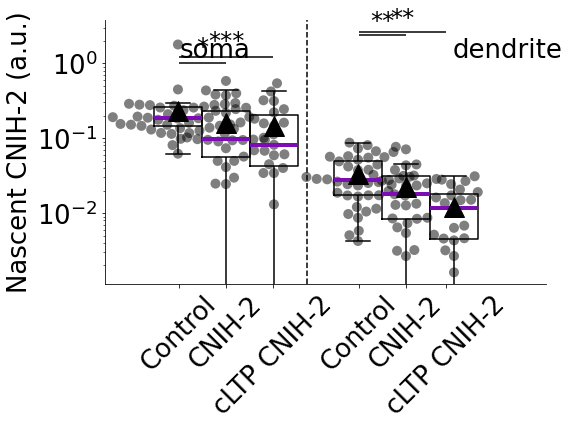

In [304]:
# compart = compartments[0]
unit_string = {compartments[0]:" \n in {} / $\mu m^2$".format(compartments[0]),compartments[1]:"\n in {} / $ \mu m$".format(compartments[1])}

xlab = ""
title = ""
ylab = r"Nascent CNIH-2 (a.u.)"
print("Subunit = ",newprot_density.groupby(["treatment","compartment"])["Density"].mean())
SwarmBoxCombo(newprot_density,
              x = "compartment",
              y = "Density",
              fbase="Fig_cLTP_cnih2_GluA2_density",
              xlabel=xlab,
              ylabel=ylab,
              title=title,
              Num = False)